In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
data=pd.read_csv(r"C:\Users\PC\Downloads\demand_forecasting.csv")
data

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,Snowy,0,32.23,Winter,0,64
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,Snowy,0,40.73,Winter,0,137
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,Snowy,0,19.41,Winter,0,68
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,Snowy,0,143.71,Winter,0,84


## Exploratory Data Analysis(EDA)

In [3]:
data.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [4]:
data.tail()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,Snowy,0,32.23,Winter,0,64
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,Snowy,0,40.73,Winter,0,137
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,Snowy,0,19.41,Winter,0,68
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,Snowy,0,143.71,Winter,0,84
75999,2024-01-30,S005,P0020,Toys,North,126,63,59,25.78,10,Snowy,0,29.32,Winter,0,73


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store ID            76000 non-null  object 
 2   Product ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  object 
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  object 
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: f

In [6]:
data.describe()

,Inventory Level,Units Sold,Units Ordered,Price,Discount,Promotion,Competitor Pricing,Epidemic,Demand
count,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000,76000.000000
mean,301.062842,88.827316,89.090645,67.726028,9.087039,0.328947,69.454029,0.200000,104.317158
std,226.510161,43.994525,162.404627,39.377899,7.475781,0.469834,40.943818,0.400003,46.964801
min,0.000000,0.000000,0.000000,4.740000,0.000000,0.000000,4.290000,0.000000,4.000000
25%,136.000000,58.000000,0.000000,31.997500,5.000000,0.000000,32.620000,0.000000,71.000000
50%,227.000000,84.000000,0.000000,64.500000,10.000000,0.000000,65.700000,0.000000,100.000000
75%,408.000000,114.000000,121.000000,95.830000,10.000000,1.000000,97.932500,0.000000,133.000000
max,2267.000000,426.000000,1616.000000,228.030000,25.000000,1.000000,261.220000,1.000000,430.000000


In [7]:
data.duplicated().any()

np.False_

In [8]:
data.isnull().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

In [9]:
data["Date"] = pd.to_datetime(data["Date"])

print("\nDate converted successfully.")

print(data["Date"].min())
print(data["Date"].max())


Date converted successfully.
2022-01-01 00:00:00
2024-01-30 00:00:00


In [10]:
data["Year"] = data["Date"].dt.year
data["Month"] = data["Date"].dt.month
data["Month_Name"] = data["Date"].dt.month_name()
data["Day"] = data["Date"].dt.day
data["Day_Name"] = data["Date"].dt.day_name()

print("\n========== DATE FEATURES ==========")
print(data[["Date", "Year", "Month", "Month_Name", "Day_Name"]].head())


========== DATE FEATURES ==========
        Date  Year  Month Month_Name  Day_Name
0 2022-01-01  2022      1    January  Saturday
1 2022-01-01  2022      1    January  Saturday
2 2022-01-01  2022      1    January  Saturday
3 2022-01-01  2022      1    January  Saturday
4 2022-01-01  2022      1    January  Saturday


## Visualizing Using Matplotlib

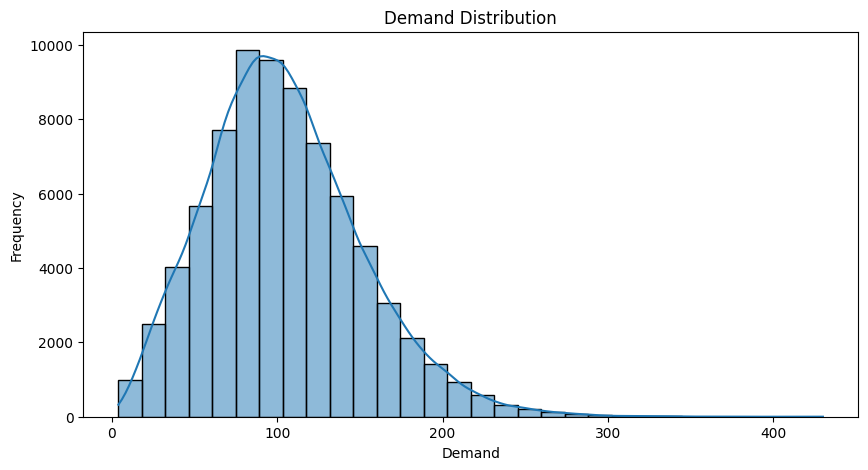

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(data["Demand"], bins=30, kde=True)

plt.title("Demand Distribution")
plt.xlabel("Demand")
plt.ylabel("Frequency")
plt.show()


========== DEMAND BY PRODUCT ==========
Product ID
P0009    450324
P0013    440895
P0004    438505
P0007    437089
P0002    425853
P0010    422064
P0001    416447
P0006    409345
P0005    408578
P0008    396538
Name: Demand, dtype: int64


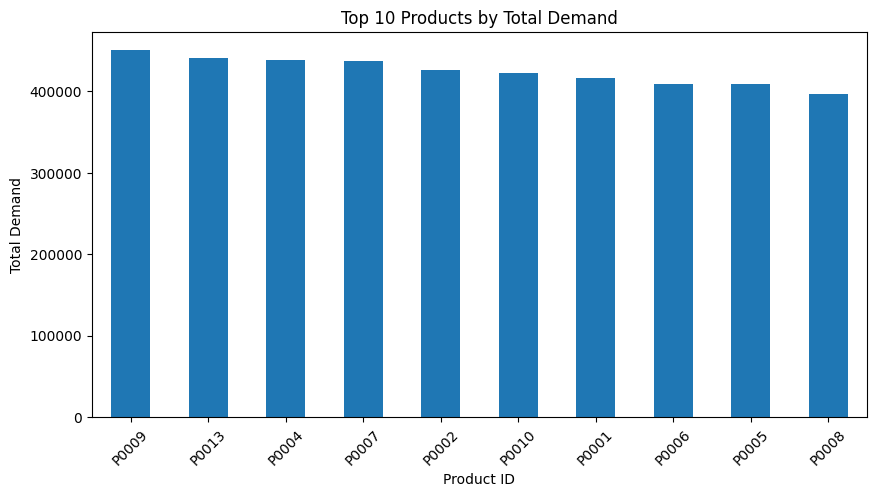

In [12]:
product_demand = (
    data.groupby("Product ID")["Demand"]
    .sum()
    .sort_values(ascending=False)
)

print("\n========== DEMAND BY PRODUCT ==========")
print(product_demand.head(10))


plt.figure(figsize=(10, 5))

product_demand.head(10).plot(kind="bar")

plt.title("Top 10 Products by Total Demand")
plt.xlabel("Product ID")
plt.ylabel("Total Demand")

plt.xticks(rotation=45)

plt.show()


========== DEMAND BY CATEGORY ==========
Category
Groceries      3677684
Clothing       1369456
Furniture      1006590
Toys            985338
Electronics     889036
Name: Demand, dtype: int64


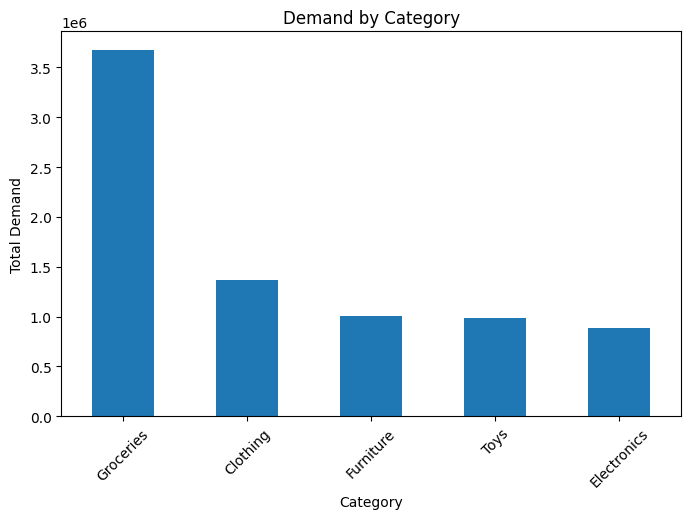

In [13]:
category_demand = (
    data.groupby("Category")["Demand"]
    .sum()
    .sort_values(ascending=False)
)

print("\n========== DEMAND BY CATEGORY ==========")
print(category_demand)


plt.figure(figsize=(8, 5))

category_demand.plot(kind="bar")

plt.title("Demand by Category")
plt.xlabel("Category")
plt.ylabel("Total Demand")

plt.xticks(rotation=45)
plt.show()



========== PROMOTION VS DEMAND ==========
Promotion
0     95.026843
1    123.269400
Name: Demand, dtype: float64


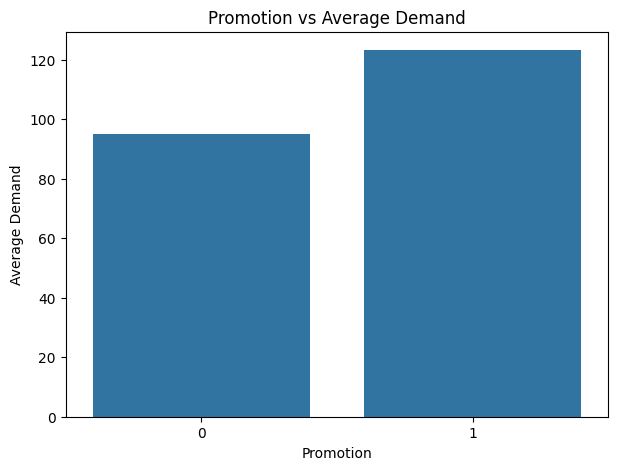

In [14]:
promotion_demand = (
    data.groupby("Promotion")["Demand"]
    .mean()
)

print("\n========== PROMOTION VS DEMAND ==========")
print(promotion_demand)


plt.figure(figsize=(7, 5))

sns.barplot(
    x=promotion_demand.index,
    y=promotion_demand.values
)

plt.title("Promotion vs Average Demand")
plt.xlabel("Promotion")
plt.ylabel("Average Demand")

plt.show()


========== DEMAND BY REGION ==========
Region
North    3154658
South    1625471
East     1618324
West     1529651
Name: Demand, dtype: int64


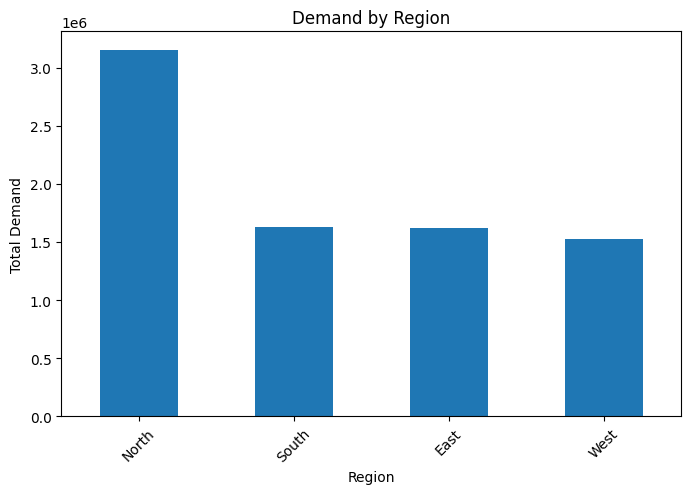

In [15]:
region_demand = (
    data.groupby("Region")["Demand"]
    .sum()
    .sort_values(ascending=False)
)

print("\n========== DEMAND BY REGION ==========")
print(region_demand)


plt.figure(figsize=(8, 5))

region_demand.plot(kind="bar")

plt.title("Demand by Region")
plt.xlabel("Region")
plt.ylabel("Total Demand")

plt.xticks(rotation=45)

plt.show()



========== WEATHER VS DEMAND ==========
Weather Condition
Sunny     115.167189
Cloudy    105.404064
Rainy      95.106743
Snowy      94.045789
Name: Demand, dtype: float64


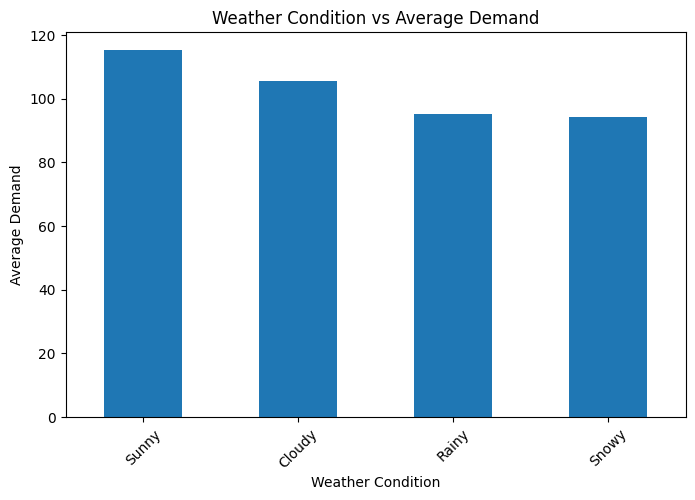

In [16]:
weather_demand = (
    data.groupby("Weather Condition")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== WEATHER VS DEMAND ==========")
print(weather_demand)


plt.figure(figsize=(8, 5))

weather_demand.plot(kind="bar")

plt.title("Weather Condition vs Average Demand")
plt.xlabel("Weather Condition")
plt.ylabel("Average Demand")

plt.xticks(rotation=45)

plt.show()


========== SEASON VS DEMAND ==========
Seasonality
Summer    112.855380
Autumn    103.422967
Winter    103.406190
Spring     97.703098
Name: Demand, dtype: float64


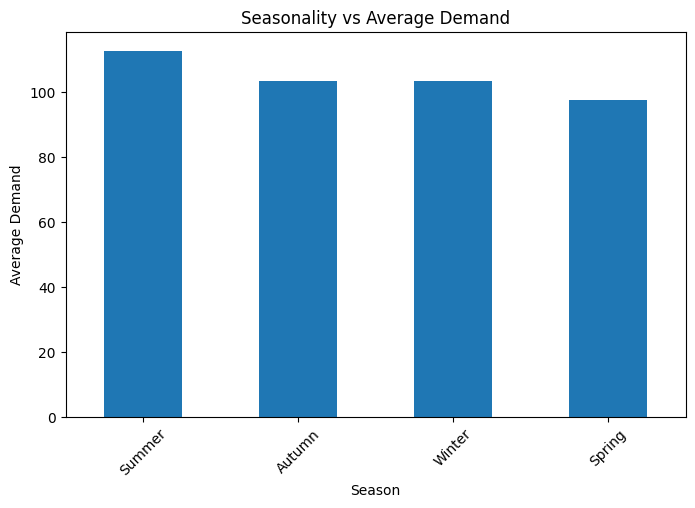

In [17]:
season_demand = (
    data.groupby("Seasonality")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== SEASON VS DEMAND ==========")
print(season_demand)


plt.figure(figsize=(8, 5))

season_demand.plot(kind="bar")

plt.title("Seasonality vs Average Demand")
plt.xlabel("Season")
plt.ylabel("Average Demand")

plt.xticks(rotation=45)

plt.show()


========== COMPETITOR PRICE CORRELATION ==========
Correlation: -0.023036445032016534


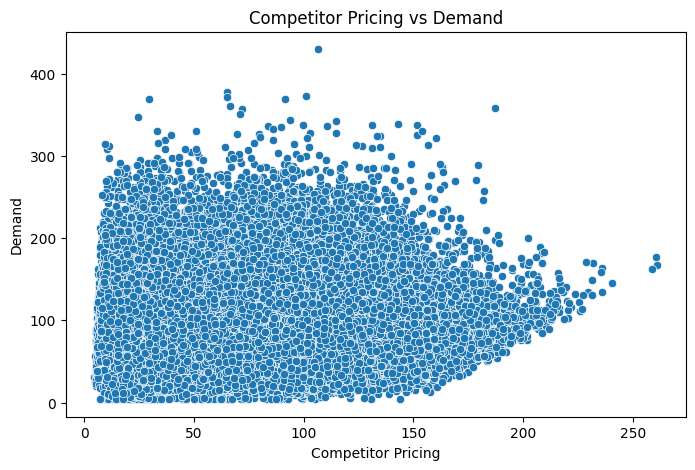

In [18]:
competitor_correlation = (
    data["Competitor Pricing"].corr(data["Demand"])
)

print("\n========== COMPETITOR PRICE CORRELATION ==========")
print("Correlation:", competitor_correlation)


plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="Competitor Pricing",
    y="Demand"
)

plt.title("Competitor Pricing vs Demand")
plt.xlabel("Competitor Pricing")
plt.ylabel("Demand")

plt.show()


========== EPIDEMIC VS DEMAND ==========
Epidemic
0    112.856743
1     70.158816
Name: Demand, dtype: float64


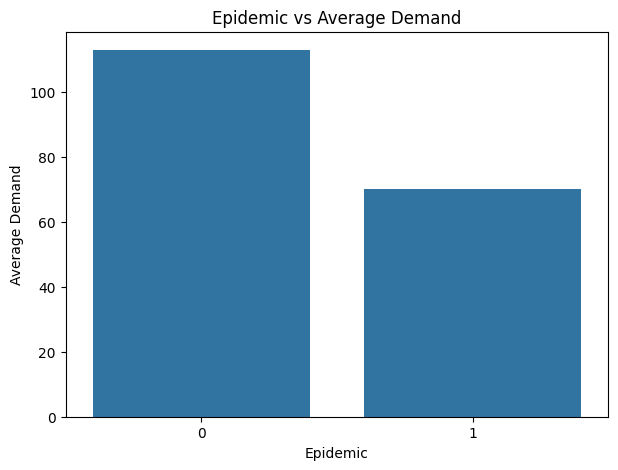

In [19]:
epidemic_demand = (
    data.groupby("Epidemic")["Demand"]
    .mean()
)

print("\n========== EPIDEMIC VS DEMAND ==========")
print(epidemic_demand)


plt.figure(figsize=(7, 5))

sns.barplot(
    x=epidemic_demand.index,
    y=epidemic_demand.values
)

plt.title("Epidemic vs Average Demand")
plt.xlabel("Epidemic")
plt.ylabel("Average Demand")

plt.show()


========== DAILY DEMAND ==========
Date
2022-01-01    10060
2022-01-02    10814
2022-01-03    11317
2022-01-04    11469
2022-01-05    11724
Name: Demand, dtype: int64


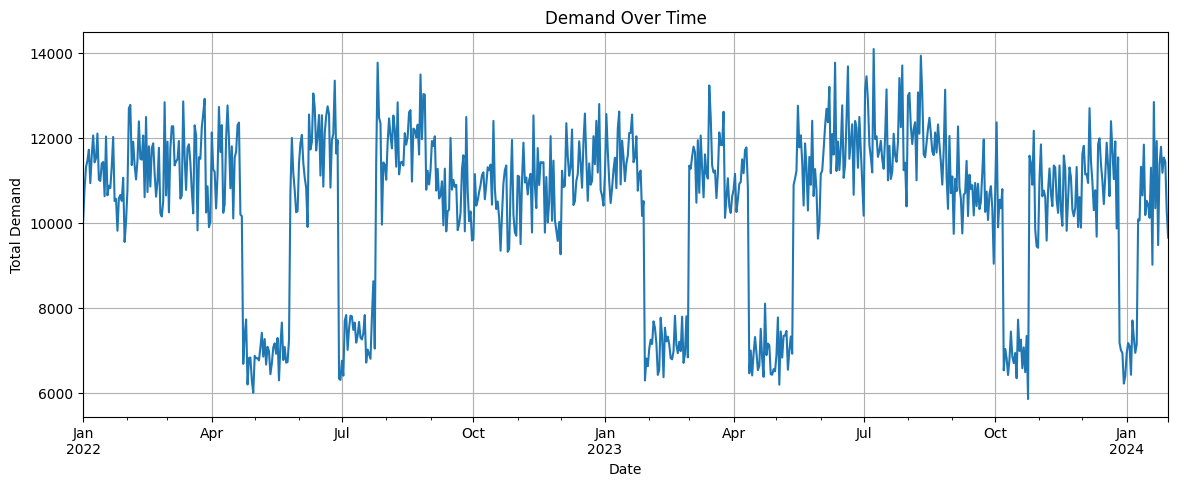

In [20]:
daily_demand = (
    data.groupby("Date")["Demand"]
    .sum()
)

print("\n========== DAILY DEMAND ==========")
print(daily_demand.head())


plt.figure(figsize=(14, 5))

daily_demand.plot()

plt.title("Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Total Demand")

plt.grid(True)

plt.show()


========== MONTHLY DEMAND ==========
Month
1     975568
2     520142
3     704406
4     556900
5     536431
6     704076
7     629682
8     742781
9     644589
10    592455
11    645254
12    675820
Name: Demand, dtype: int64


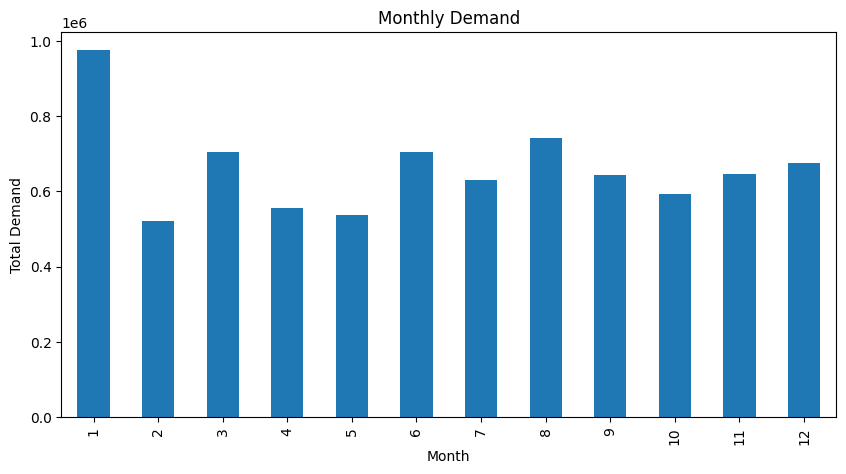

In [21]:
monthly_demand = (
    data.groupby("Month")["Demand"]
    .sum()
)

print("\n========== MONTHLY DEMAND ==========")
print(monthly_demand)


plt.figure(figsize=(10, 5))

monthly_demand.plot(kind="bar")

plt.title("Monthly Demand")
plt.xlabel("Month")
plt.ylabel("Total Demand")

plt.show()


========== YEARLY DEMAND ==========
Year
2022    3862652
2023    3771293
2024     294159
Name: Demand, dtype: int64


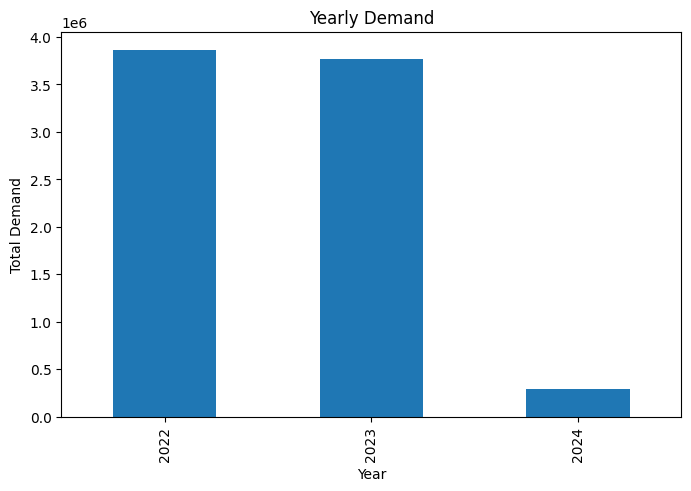

In [22]:
yearly_demand = (
    data.groupby("Year")["Demand"]
    .sum()
)

print("\n========== YEARLY DEMAND ==========")
print(yearly_demand)


plt.figure(figsize=(8, 5))

yearly_demand.plot(kind="bar")

plt.title("Yearly Demand")
plt.xlabel("Year")
plt.ylabel("Total Demand")

plt.show()


========== CORRELATION MATRIX ==========
                        Store ID    Product ID      Category        Region  \
Store ID            1.000000e+00 -2.718873e-17  7.129525e-02  1.386750e-01   
Product ID         -2.718873e-17  1.000000e+00 -1.425746e-01 -6.191586e-18   
Category            7.129525e-02 -1.425746e-01  1.000000e+00 -1.870900e-01   
Region              1.386750e-01 -6.191586e-18 -1.870900e-01  1.000000e+00   
Inventory Level    -2.077567e-02 -1.057383e-01  3.779439e-02 -4.862068e-03   
Units Sold          2.415348e-03 -1.196813e-01  2.723312e-02 -2.154258e-02   
Units Ordered       5.027736e-04 -3.269883e-02  7.342610e-03 -5.788353e-03   
Price              -1.311774e-02  3.128303e-01 -4.120361e-01  6.816893e-02   
Discount            3.011848e-03 -3.192014e-03  5.607018e-03  4.038610e-04   
Weather Condition   1.341035e-02  3.093903e-16 -3.087248e-03  1.961118e-02   
Promotion          -1.451715e-17  9.262147e-17 -5.270817e-17 -8.150383e-18   
Competitor Pricing -1.

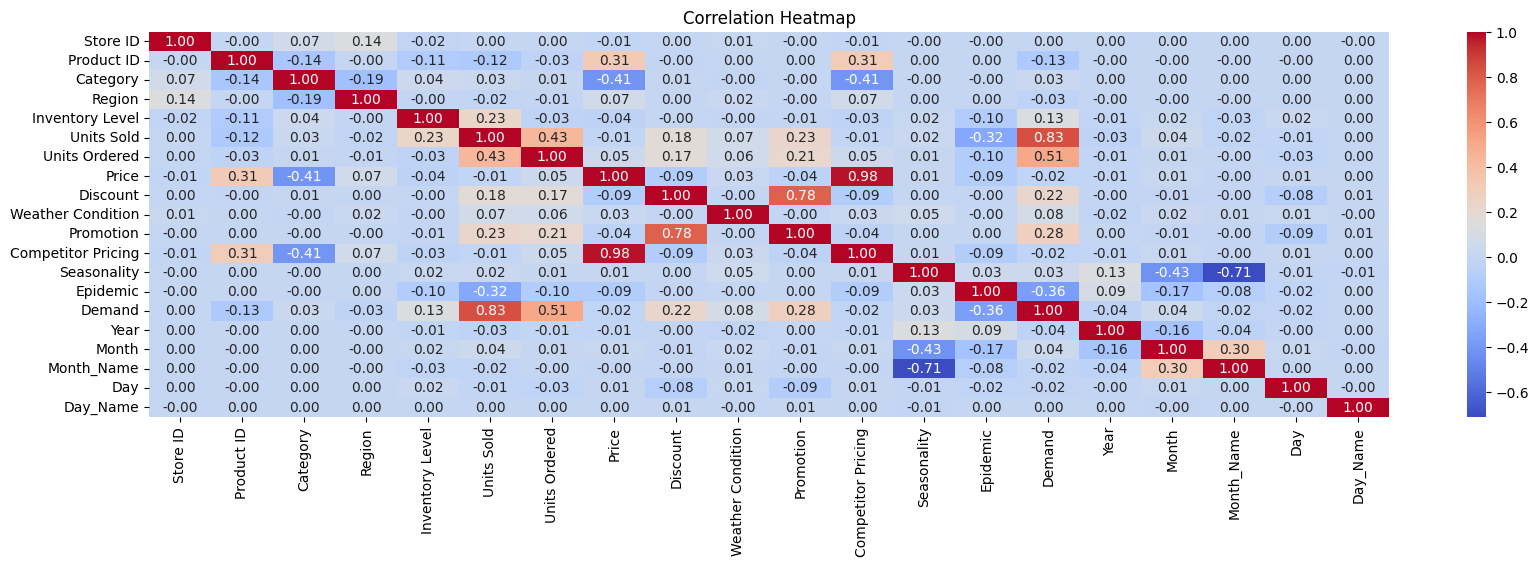

In [71]:
numeric_columns = data.select_dtypes(
    include=np.number
)

correlation = numeric_columns.corr()

print("\n========== CORRELATION MATRIX ==========")
print(correlation)


plt.figure(figsize=(20, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

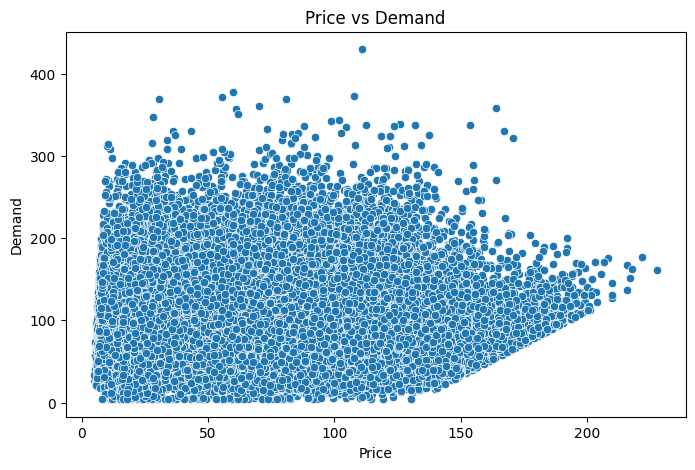

In [24]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="Price",
    y="Demand"
)

plt.title("Price vs Demand")
plt.xlabel("Price")
plt.ylabel("Demand")

plt.show()

In [25]:
avg_category_demand = (
    data.groupby("Category")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== AVERAGE DEMAND BY CATEGORY ==========")
print(avg_category_demand)


========== AVERAGE DEMAND BY CATEGORY ==========
Category
Groceries      120.976447
Clothing       112.619737
Electronics     97.482018
Toys            92.606955
Furniture       73.581140
Name: Demand, dtype: float64


In [26]:
avg_region_demand = (
    data.groupby("Region")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== AVERAGE DEMAND BY REGION ==========")
print(avg_region_demand)


========== AVERAGE DEMAND BY REGION ==========
Region
South    106.938882
East     106.468684
North    103.771645
West     100.634934
Name: Demand, dtype: float64


In [27]:
avg_season_demand = (
    data.groupby("Seasonality")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== AVERAGE DEMAND BY SEASON ==========")
print(avg_season_demand)


========== AVERAGE DEMAND BY SEASON ==========
Seasonality
Summer    112.855380
Autumn    103.422967
Winter    103.406190
Spring     97.703098
Name: Demand, dtype: float64


In [28]:
avg_weather_demand = (
    data.groupby("Weather Condition")["Demand"]
    .mean()
    .sort_values(ascending=False)
)

print("\n========== AVERAGE DEMAND BY WEATHER ==========")
print(avg_weather_demand)


========== AVERAGE DEMAND BY WEATHER ==========
Weather Condition
Sunny     115.167189
Cloudy    105.404064
Rainy      95.106743
Snowy      94.045789
Name: Demand, dtype: float64


In [29]:
print("\n========== PROMOTION COMPARISON ==========")

promotion_comparison = data.groupby("Promotion").agg(
    Average_Demand=("Demand", "mean"),
    Total_Demand=("Demand", "sum"),
    Number_of_Records=("Demand", "count")
)

print(promotion_comparison)


========== PROMOTION COMPARISON ==========
           Average_Demand  Total_Demand  Number_of_Records
Promotion                                                 
0               95.026843       4846369              51000
1              123.269400       3081735              25000


In [30]:
print("\n========== EPIDEMIC COMPARISON ==========")

epidemic_comparison = data.groupby("Epidemic").agg(
    Average_Demand=("Demand", "mean"),
    Total_Demand=("Demand", "sum"),
    Number_of_Records=("Demand", "count")
)

print(epidemic_comparison)


========== EPIDEMIC COMPARISON ==========
          Average_Demand  Total_Demand  Number_of_Records
Epidemic                                                 
0             112.856743       6861690              60800
1              70.158816       1066414              15200


In [31]:
print("\n========== TOP 10 DEMAND RECORDS ==========")

top_demand = data.sort_values(
    by="Demand",
    ascending=False
).head(10)

print(top_demand)


========== TOP 10 DEMAND RECORDS ==========
            Date Store ID Product ID   Category Region  Inventory Level  \
54387 2023-06-28     S005      P0008  Groceries  North              227   
21915 2022-08-08     S001      P0016  Groceries  North              339   
21885 2022-08-07     S005      P0006  Groceries  North              299   
53415 2023-06-19     S001      P0016  Groceries  North              619   
60261 2023-08-26     S004      P0002  Groceries   West              296   
15994 2022-06-09     S005      P0015  Groceries  North              144   
6745  2022-03-09     S003      P0006       Toys   East              170   
16254 2022-06-12     S003      P0015  Groceries   East             1000   
16165 2022-06-11     S004      P0006  Groceries   West              294   
53023 2023-06-15     S002      P0004  Groceries  South              987   

       Units Sold  Units Ordered   Price  Discount  ... Promotion  \
54387         227            489  110.86        20  ...     

In [32]:
print("\n========== LOWEST 10 DEMAND RECORDS ==========")

low_demand = data.sort_values(
    by="Demand",
    ascending=True
).head(10)

print(low_demand)


========== LOWEST 10 DEMAND RECORDS ==========
            Date Store ID Product ID   Category Region  Inventory Level  \
75491 2024-01-25     S005      P0012  Furniture  North              218   
17367 2022-06-23     S004      P0008  Furniture   West              179   
42336 2023-02-28     S002      P0017       Toys  South              134   
54034 2023-06-25     S002      P0015   Clothing  South              351   
3206  2022-02-02     S001      P0007  Groceries  North              504   
4796  2022-02-17     S005      P0017       Toys  North               98   
7287  2022-03-14     S005      P0008  Groceries  North              147   
48193 2023-04-27     S005      P0014  Furniture  North              282   
19505 2022-07-15     S001      P0006       Toys  North              180   
20118 2022-07-21     S001      P0019  Furniture  North               94   

       Units Sold  Units Ordered   Price  Discount  ... Promotion  \
75491           4              0   77.45        20  ...  

In [33]:
print("\n==========================================")
print("       FINAL DATASET SUMMARY")
print("==========================================")

print("Total Rows:", len(data))
print("Total Columns:", len(data.columns))
print("Missing Values:", data.isnull().sum().sum())
print("Duplicate Rows:", data.duplicated().sum())
print("Minimum Demand:", data["Demand"].min())
print("Maximum Demand:", data["Demand"].max())
print("Average Demand:", data["Demand"].mean())




       FINAL DATASET SUMMARY
Total Rows: 76000
Total Columns: 21
Missing Values: 0
Duplicate Rows: 0
Minimum Demand: 4
Maximum Demand: 430
Average Demand: 104.31715789473684


In [34]:

data["Price"] = data["Price"].astype(int)
data["Competitor Pricing"] = data["Competitor Pricing"].astype(int)

data=data.drop('Date',axis=1)

### Converting Categorical Values Into Numerical Values

In [35]:
data.dtypes

Store ID              object
Product ID            object
Category              object
Region                object
Inventory Level        int64
Units Sold             int64
Units Ordered          int64
Price                  int64
Discount               int64
Weather Condition     object
Promotion              int64
Competitor Pricing     int64
Seasonality           object
Epidemic               int64
Demand                 int64
Year                   int32
Month                  int32
Month_Name            object
Day                    int32
Day_Name              object
dtype: object

In [36]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split



In [37]:
obj1=LabelEncoder()
obj2=LabelEncoder()
obj3=LabelEncoder()
obj4=LabelEncoder()
obj5=LabelEncoder()
obj6=LabelEncoder()
obj7=LabelEncoder()
obj8=LabelEncoder()
data['Store ID']=obj1.fit_transform(data['Store ID'])
data['Product ID']=obj2.fit_transform(data['Product ID'])
data['Category']=obj3.fit_transform(data['Category'])
data['Region']=obj4.fit_transform(data['Region'])
data['Weather Condition']=obj5.fit_transform(data['Weather Condition'])
data['Seasonality']=obj6.fit_transform(data['Seasonality'])
data['Month_Name']=obj7.fit_transform(data['Month_Name'])
data['Day_Name']=obj8.fit_transform(data['Day_Name'])


import joblib


# Save the encoders for later use
joblib.dump(obj1, "obj1_encoder.pkl")
joblib.dump(obj2, "obj2_encoder.pkl")
joblib.dump(obj3, "obj3_encoder.pkl")
joblib.dump(obj4, "obj4_encoder.pkl")
joblib.dump(obj5, "obj5_encoder.pkl")
joblib.dump(obj6, "obj6_encoder.pkl")
joblib.dump(obj7, "obj7_encoder.pkl")
joblib.dump(obj8, "obj8_encoder.pkl")




['obj8_encoder.pkl']

In [38]:
data.dtypes

Store ID              int64
Product ID            int64
Category              int64
Region                int64
Inventory Level       int64
Units Sold            int64
Units Ordered         int64
Price                 int64
Discount              int64
Weather Condition     int64
Promotion             int64
Competitor Pricing    int64
Seasonality           int64
Epidemic              int64
Demand                int64
Year                  int32
Month                 int32
Month_Name            int64
Day                   int32
Day_Name              int64
dtype: object

# Selecting Target Value

In [39]:
x=data.drop(['Demand'],axis=1)
y=data['Demand']

In [40]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.3,random_state=1)

# Model Fitting

# Linear Regression

In [41]:
model1=LinearRegression()
model1.fit(xtrain,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [42]:
model1.predict(xtest)
lineartrain=model1.score(xtrain,ytrain)*100
lineartrain

74.45379954440699

In [43]:
lineartest=model1.score(xtest,ytest)*100
lineartest

75.32320154902217

In [44]:
model2=DecisionTreeRegressor()
model2.fit(xtrain,ytrain)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [45]:
model2.predict(xtest)
Treetrain=model2.score(xtrain,ytrain)*100
Treetrain

100.0

In [46]:
treetest=model2.score(xtest,ytest)*100
treetest

73.87662750348967

#

In [47]:
model3=RandomForestRegressor(n_estimators=50,random_state=1)
model3.fit(xtrain,ytrain)

,n_estimators,50
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [48]:
model3.predict(xtest)

array([139.46,  55.8 ,  60.06, ...,  71.64, 122.58,  70.5 ],
      shape=(22800,))

In [49]:
foresttrain=model3.score(xtrain,ytrain)*100
foresttrain

98.03921784583513

In [50]:
foresttest=model3.score(xtest,ytest)*100
foresttest

86.69092286819425

In [51]:
model4=KNeighborsRegressor(n_neighbors=9)
model4.fit(xtrain,ytrain)

,n_neighbors,9
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [52]:
model4.predict(xtest)

array([128.        ,  42.44444444,  70.66666667, ...,  78.88888889,
       108.33333333,  80.11111111], shape=(22800,))

In [53]:
neighbortrain=model4.score(xtrain,ytrain)*100
neighbortrain

85.82305523659876

In [54]:
neighbortest=model4.score(xtest,ytest)*100
neighbortest

82.66686786445466

In [55]:
model5=AdaBoostRegressor(n_estimators=50,random_state=1)
model5.fit(xtrain,ytrain)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,loss,'linear'
,random_state,1


In [56]:
model5.predict(xtest)

array([152.53192115, 112.53517588,  85.47946514, ...,  93.64313195,
       133.22118588,  93.59407985], shape=(22800,))

In [57]:
Adaboosttrain=model5.score(xtrain,ytrain)*100
Adaboosttrain

61.80271650067268

In [58]:
Adaboosttest=model5.score(xtest,ytest)*100
Adaboosttest

61.69216088700355

In [59]:
model6=GradientBoostingRegressor(n_estimators=50,random_state=1)
model6.fit(xtrain,ytrain)


,loss,'squared_error'
,learning_rate,0.1
,n_estimators,50
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [60]:
model6.predict(xtest)

array([138.73978476,  83.23669718,  66.99477198, ...,  84.74910434,
       123.23554896,  73.61481721], shape=(22800,))

In [61]:
gradienttrain=model6.score(xtrain,ytrain)*100
gradienttrain

83.45483150800928

In [62]:
gradienttest=model6.score(xtest,ytest)*100
gradienttest

83.63564467211233

## Representing Models Training and Testing Score Graphically


In [63]:
score=pd.DataFrame({'Model':['LinearRegression','DecisionTreeRegression','RandomForestRegressor',
                           'KNeighborRegressor','AdaBoostRegressor','GradientBoostRegressor'],
                    'TrainingScores': [lineartrain,Treetrain,foresttrain,neighbortrain,Adaboosttrain,gradienttrain],
                    'TestingScore': [lineartest,treetest,foresttest,neighbortest,Adaboosttest,gradienttest]})
score

,Model,TrainingScores,TestingScore
0,LinearRegression,74.453800,75.323202
1,DecisionTreeRegression,100.000000,73.876628
2,RandomForestRegressor,98.039218,86.690923
3,KNeighborRegressor,85.823055,82.666868
4,AdaBoostRegressor,61.802717,61.692161
5,GradientBoostRegressor,83.454832,83.635645


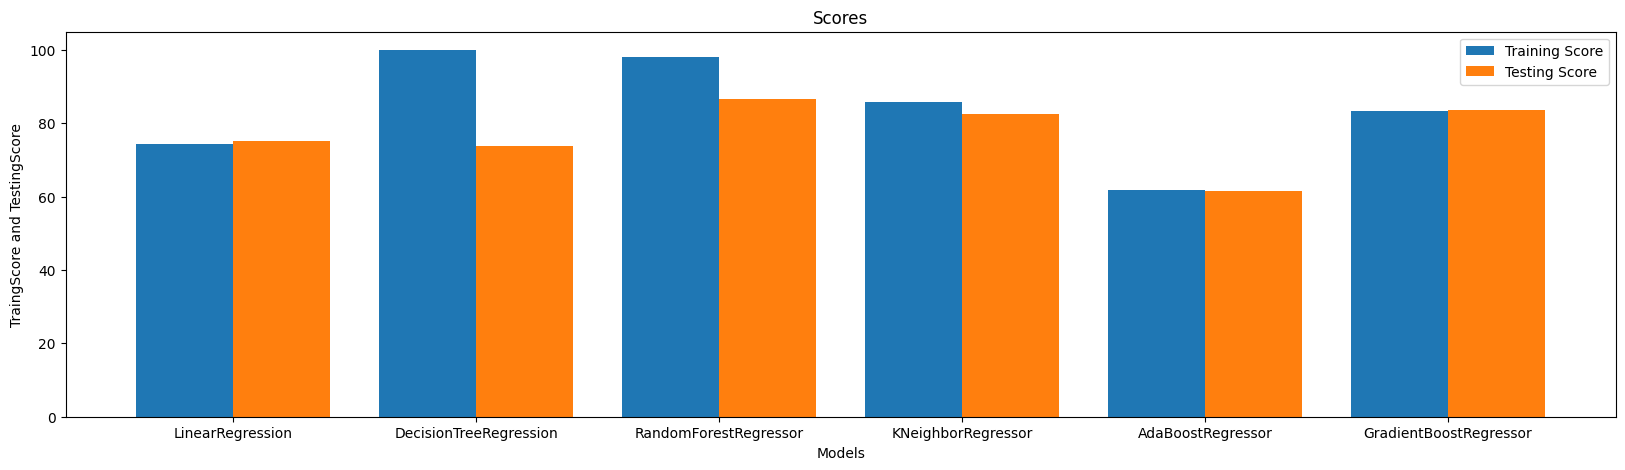

In [64]:
x=score.Model
y=score.TrainingScores
z=score.TestingScore
width=0.4
x_indices = np.arange(len(x))
plt.figure(figsize=(20,5))
plt.bar(x_indices - width / 2, y, width=width, label='Training Score')
plt.bar(x_indices + width / 2, z, width=width, label='Testing Score')
plt.xticks(x_indices, x)
plt.xlabel('Models')
plt.ylabel('TraingScore and TestingScore')
plt.title("Scores")
plt.legend()
plt.show()

In [65]:
models = {

    "Linear Regression":
        LinearRegression(),

    "Decision Tree":
        DecisionTreeRegressor(
            max_depth=10,
            random_state=42
        ),

    "Random Forest":
        RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ),

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ),

    "KNN":
        KNeighborsRegressor(
            n_neighbors=5
        )
}


In [66]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

In [67]:

results = []

predictions = {}

for name, model in models.items():

    # Train model
    model.fit(xtrain,ytrain)

    # Prediction
    prediction = model.predict(xtest)

    # Save prediction
    predictions[name] = prediction

    # Evaluation
    mae = mean_absolute_error(
        ytest,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            ytest,
            prediction
        )
    )

    r2 = r2_score(
        ytest,
        prediction
    )*100

    results.append([
        name,
        mae,
        rmse,
        r2
    ])

In [68]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "RMSE",
        "R2 Score"
    ]
)

print("\n========== MODEL COMPARISON ==========")

print(results_df)


========== MODEL COMPARISON ==========
               Model        MAE       RMSE   R2 Score
0  Linear Regression  17.373000  23.326541  75.323202
1      Decision Tree  14.218228  19.157776  83.355210
2      Random Forest  12.850534  17.064033  86.794601
3  Gradient Boosting  13.874289  18.140412  85.076096
4                KNN  14.841456  20.196187  81.501909


In [69]:
best_index = results_df["R2 Score"].idxmax()

best_model_name = results_df.loc[
    best_index,
    "Model"
]

best_prediction = predictions[
    best_model_name
]

print("\n========== BEST MODEL ==========")

print("Best Model:", best_model_name)

print(
    "Best R2 Score:",
    results_df.loc[
        best_index,
        "R2 Score"
    ]
)


========== BEST MODEL ==========
Best Model: Random Forest
Best R2 Score: 86.79460146171422


In [70]:
joblib.dump(model3, "random_forest.pkl")

['random_forest.pkl']